# **Fuel Data Prediction Model**

### **Step - 1 ( Problem Definition )**

**Problem -** A logistic company wants to estimate how many liters of fuel a vehicle will consume for a trip based only on the travel distance.

**Objective -** Predict fuel consumption using travel distance.

*   **Feature (X)** - Distance (Km)
*   **Target (Y)** - Fuel Used (L)

Since fuel used in a continous **numeric value**, this is a **Supervised Regression** problem.

### **Step - 2 ( Data Collection )**

In [168]:
import pandas as pd

df = pd.read_csv("/content/full_fuel_data (1).csv")

df.head()

,Distance_km,Fuel_Used_Liters
0,10,0.95
1,15,1.32
2,20,1.48
3,25,1.90
4,30,2.55


### **Step - 3 ( Data Understanding (EDA) )**

In [169]:
df.head()

,Distance_km,Fuel_Used_Liters
0,10,0.95
1,15,1.32
2,20,1.48
3,25,1.90
4,30,2.55


In [170]:
df.shape

(62, 2)

In [171]:
df.dtypes

,0
Distance_km,int64
Fuel_Used_Liters,float64


In [172]:
df.describe()

,Distance_km,Fuel_Used_Liters
count,62.000000,60.000000
mean,152.016129,12.028833
std,85.379863,6.777124
min,10.000000,0.950000
25%,81.250000,6.322500
50%,150.000000,12.020000
75%,223.750000,17.670000
max,300.000000,24.220000


In [173]:
df.isnull().sum()

,0
Distance_km,0
Fuel_Used_Liters,2


In [174]:
df.duplicated().sum()

np.int64(3)

<function matplotlib.pyplot.show(close=None, block=None)>

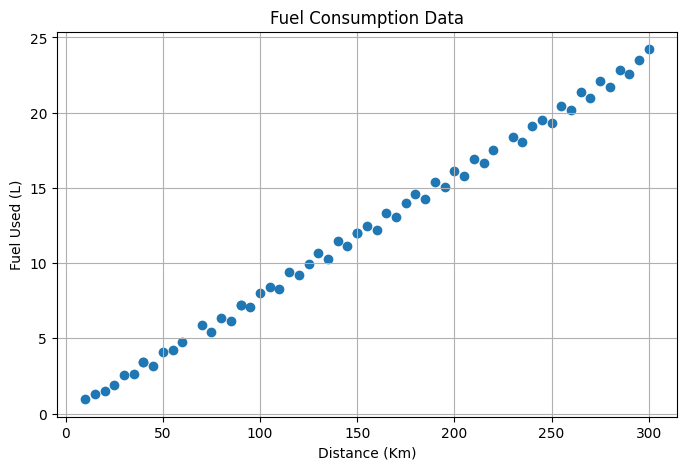

In [175]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.title("Fuel Consumption Data")
plt.scatter(df["Distance_km"], df["Fuel_Used_Liters"])
plt.xlabel("Distance (Km)")
plt.ylabel("Fuel Used (L)")
plt.grid(True)
plt.show

### **Step - 4 ( Data Cleaning )**

In [176]:
print(df.isnull().sum())
print(df.duplicated().sum())

Distance_km         0
Fuel_Used_Liters    2
dtype: int64
3


**Handle Missing Values**

1.   Remove Missing Rows
2.   Replace Missing Values with Mean


*Remove Duplicates*

In [177]:
df = df.drop_duplicates()

print(df.isnull().sum())
print(df.duplicated().sum())

Distance_km         0
Fuel_Used_Liters    2
dtype: int64
0


*Replace with Mean Value*

In [178]:
# df["Fuel_Used_Liters"] = df["Fuel_Used_Liters"].fillna(df["Fuel_Used_Liters"].mean())

# print(df.isnull().sum())
# print(df.duplicated().sum())

*Remove Null Values*

In [179]:
df = df.dropna()

print(df.isnull().sum())
print(df.duplicated().sum())

Distance_km         0
Fuel_Used_Liters    0
dtype: int64
0


### **Step - 5 ( Feature Engineering )**

*Feature Selection*

In [180]:
X = df[['Distance_km']]
y = df[['Fuel_Used_Liters']]

### **Step - 6 ( Split the Dataset )**

In [181]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### **Step - 7 ( Select an ML Algorithm )**

In [182]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

### **Step - 8 ( Train the Model )**

In [183]:
model.fit(X_train, y_train)

LinearRegression()

### **Step - 9 ( Evaluate the Model )**

In [184]:
y_pred = model.predict(X_test)

In [185]:
# Mean Absolute Error
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error : {mae}")

Mean Absolute Error : 0.23874160803768443


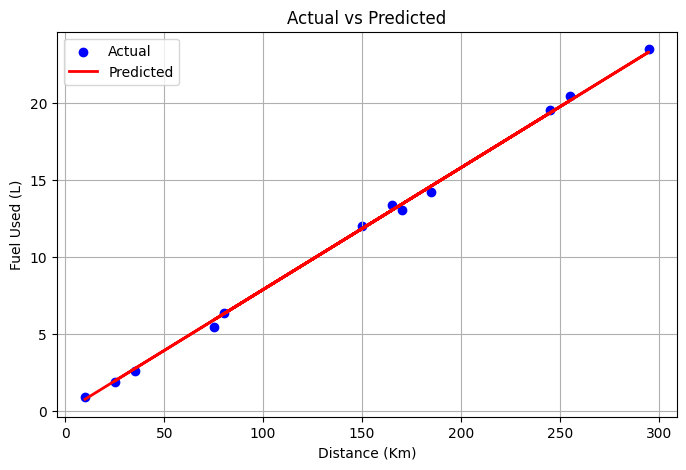

In [186]:
plt.figure(figsize=(8,5))
plt.title("Actual vs Predicted")
plt.scatter(X_test, y_test, color='blue', label='Actual')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Predicted')
plt.xlabel("Distance (Km)")
plt.ylabel("Fuel Used (L)")
plt.legend()
plt.grid(True)
plt.show()

In [187]:
distance = 175
prediction = model.predict([[distance]])

print(f"Estimate Fuel : {prediction[0]} Liters")

print(model.coef_)
print(model.intercept_)

Estimate Fuel : [13.81612494] Liters
[[0.07900792]]
[-0.01026087]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# **House Price Prediction Model**

### Section 01

A real state company wants to predict the selling price of houses using important property information.

*   **Feature 1 (X1) ->** Size
*   **Feature 2 (X2) ->** No. of beds
*   **Feature 3 (X3) ->** Age
*   **Target (Y) ->** Price





### Section 02

Assume the company collected historical house sales data.

In [188]:
import pandas as pd

df = pd.read_csv("house_prices.csv")

### Section 03

In [189]:
df.head()

,Size_sqft,Bedrooms,Age_Years,Price
0,850,2,15,185000
1,900,2,12,205000
2,950,2,10,225000
3,1000,3,12,250000
4,1100,3,8,285000


In [190]:
df.shape

(50, 4)

In [191]:
df.dtypes

,0
Size_sqft,int64
Bedrooms,int64
Age_Years,int64
Price,int64


In [192]:
df.describe()

,Size_sqft,Bedrooms,Age_Years,Price
count,50.000000,50.000000,50.000000,5.000000e+01
mean,2095.000000,4.660000,9.360000,6.274000e+05
std,772.568602,1.533437,6.036488,2.953763e+05
min,850.000000,2.000000,1.000000,1.850000e+05
25%,1462.500000,3.250000,5.000000,3.850000e+05
50%,2075.000000,5.000000,8.000000,6.000000e+05
75%,2687.500000,6.000000,13.500000,8.525000e+05
max,3800.000000,8.000000,25.000000,1.320000e+06


In [193]:
df.isnull().sum()

,0
Size_sqft,0
Bedrooms,0
Age_Years,0
Price,0


In [194]:
df.duplicated().sum()

np.int64(0)

### Section 04

<function matplotlib.pyplot.show(close=None, block=None)>

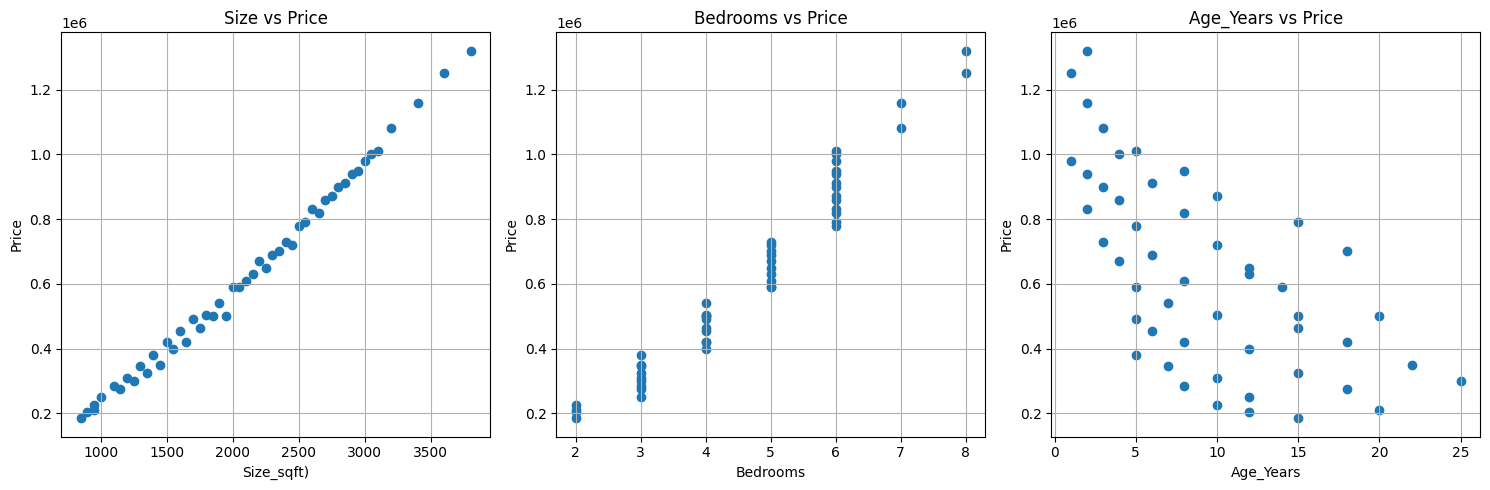

In [195]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15,5))

# Plot 1 : Size_sqft vs Price
axes[0].scatter(df["Size_sqft"], df["Price"])
axes[0].set_xlabel("Size_sqft)")
axes[0].set_ylabel("Price")
axes[0].set_title("Size vs Price")
axes[0].grid(True)

# Plot 2 : Bedroom vs Price
axes[1].scatter(df["Bedrooms"], df["Price"])
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("Price")
axes[1].set_title("Bedrooms vs Price")
axes[1].grid(True)

# Plot 3 : Age_years vs Price
axes[2].scatter(df["Age_Years"], df["Price"])
axes[2].set_xlabel("Age_Years")
axes[2].set_ylabel("Price")
axes[2].set_title("Age_Years vs Price")
axes[2].grid(True)

plt.tight_layout()
plt.show

#### Visualize All Features in 3D

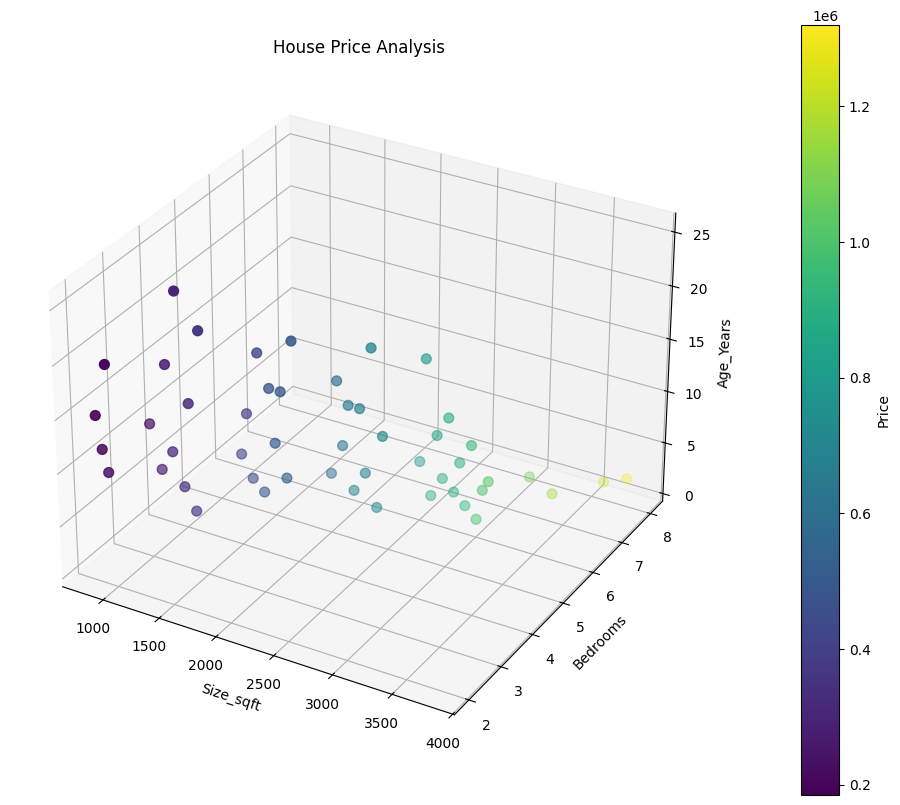

In [196]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Scatter Plot
scatter = ax.scatter(
    df["Size_sqft"],
    df["Bedrooms"],
    df["Age_Years"],
    c=df["Price"],
    cmap='viridis', # Choose a colormap
    s=50 # Size of points
)

ax.set_xlabel("Size_sqft")
ax.set_ylabel("Bedrooms")
ax.set_zlabel("Age_Years")
ax.set_title("House Price Analysis")

# Color Bar
cbar = fig.colorbar(scatter, ax=ax, pad=0.1)
cbar.set_label("Price")

plt.show()

### Section 4

### Section 5

##### Features (X)

In [197]:
X = df[["Size_sqft", "Bedrooms", "Age_Years"]]
X.head()

,Size_sqft,Bedrooms,Age_Years
0,850,2,15
1,900,2,12
2,950,2,10
3,1000,3,12
4,1100,3,8


##### Target (y)

In [198]:
y = df["Price"]
y.head()

,Price
0,185000
1,205000
2,225000
3,250000
4,285000


### Section 6

In [199]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Section 7

In [200]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

### Section 8

In [201]:
model.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


### Section 9

In [202]:
new_house_data = [[2200, 4, 5]] # Size = 2200 sqft, Bedrooms = 4, Age = 5 Years
prediction = model.predict(new_house_data)
print(f"Predicted Price : {prediction[0]}")

Predicted Price : 683774.4925947799


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [203]:
# Mean Absolute Error
from sklearn.metrics import mean_absolute_error

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error : {mae}")

Mean Absolute Error : 18814.99984473123


# **Fuel Consumption Prediction Model**

In [204]:
import pandas as pd

df = pd.read_csv("fuel_consumption.csv")
df.head()

,Speed,Fuel_Consumption
0,10,8
1,20,10
2,30,15
3,40,22
4,50,31


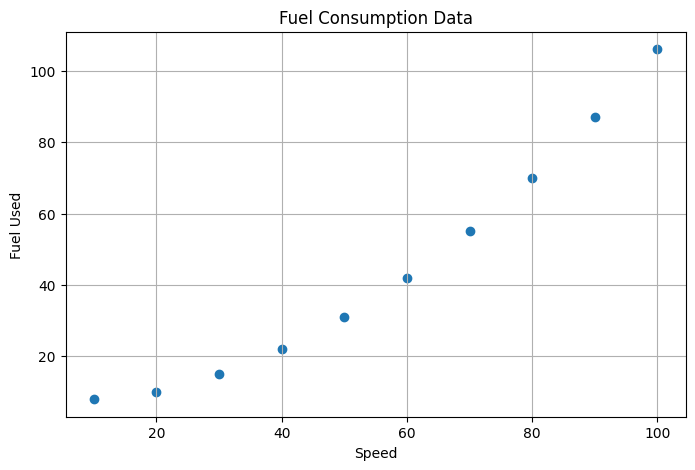

In [205]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

X = df["Speed"]
y = df["Fuel_Consumption"]
plt.scatter(X, y)

plt.title("Fuel Consumption Data")
plt.xlabel("Speed")
plt.ylabel("Fuel Used")

plt.grid(True)
plt.show()

### Split the dataset

In [206]:
X = df[['Speed']]
y = df['Fuel_Consumption']

##### *Linear Regression*

In [207]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X,y)

LinearRegression()

In [208]:
linear_predictions = linear_model.predict(X)

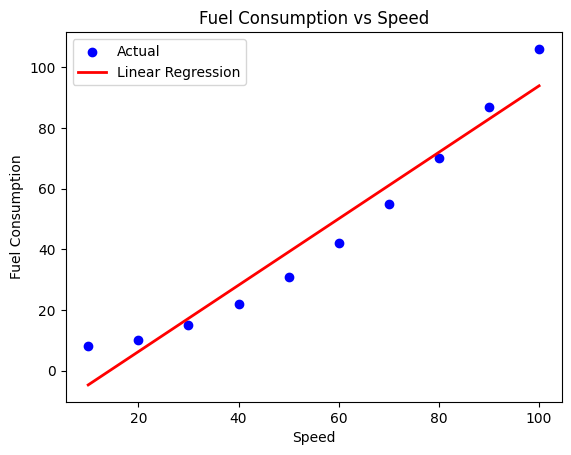

In [209]:
import matplotlib.pyplot as plt

plt.scatter(X, y, color='blue', label='Actual')
plt.plot(X, linear_predictions, color='red', linewidth=2, label='Linear Regression')
plt.xlabel('Speed')
plt.ylabel('Fuel Consumption')
plt.title('Fuel Consumption vs Speed')
plt.legend()
plt.show()

##### *Polynomial Regression*

In [210]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

In [211]:
X.head()

,Speed
0,10
1,20
2,30
3,40
4,50


In [212]:
X_poly[:3]

array([[  1.,  10., 100.],
       [  1.,  20., 400.],
       [  1.,  30., 900.]])

In [213]:
poly_model = LinearRegression()
poly_model.fit(X_poly, y)

LinearRegression()

In [214]:
import numpy as np

speed = np.array([[75]])
speed_poly = poly.fit_transform(speed)
ploy_predictions = poly_model.predict(speed_poly)

print(f"Predicted Fuel Consumption : {ploy_predictions[0]}")

Predicted Fuel Consumption : 62.14431818181819


In [215]:
# Mean Absolute Error (MAE)
from sklearn.metrics import mean_absolute_error

y_pred = poly_model.predict(X_poly)
mae = mean_absolute_error(y, y_pred)
print(f"Mean Absolute Error : {mae}")

Mean Absolute Error : 0.14909090909091044


student pass fail search

In [216]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [217]:

import pandas as pd
import os

# Find the existing CSV file
csv_files = [
    f for f in os.listdir("/content")
    if f.endswith(".csv")
    and f.startswith("student_performance_logistic")
]

print("Found CSV Files:", csv_files)

# Load dataset
file_name = os.path.join("/content", csv_files[0])
df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
display(df.head())


Found CSV Files: ['student_performance_logistic_regression (2).csv', 'student_performance_logistic_regression.csv', 'student_performance_logistic_regression (1).csv']
Dataset Loaded Successfully!


,StudyHoursPerDay,AttendancePercent,PreviousExamScore,AssignmentsCompleted,SleepHours,Passed
0,5.5,71,56,8,6.3,0
1,4.3,61,75,10,5.0,0
2,3.0,75,49,4,7.9,0
3,1.9,65,43,2,7.2,0
4,1.0,79,60,0,6.8,1


In [218]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Shape: (600, 6)

Column Names:
['StudyHoursPerDay', 'AttendancePercent', 'PreviousExamScore', 'AssignmentsCompleted', 'SleepHours', 'Passed']

Missing Values:
StudyHoursPerDay        0
AttendancePercent       0
PreviousExamScore       0
AssignmentsCompleted    0
SleepHours              0
Passed                  0
dtype: int64

Duplicate Rows:
0


In [219]:

# Create a working copy
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

print("Shape after removing duplicates:", df.shape)
print("Missing values:")
print(df.isnull().sum())


Shape after removing duplicates: (600, 6)
Missing values:
StudyHoursPerDay        0
AttendancePercent       0
PreviousExamScore       0
AssignmentsCompleted    0
SleepHours              0
Passed                  0
dtype: int64


In [220]:

print("Available Columns:")

for col in df.columns:
    print(col)


Available Columns:
StudyHoursPerDay
AttendancePercent
PreviousExamScore
AssignmentsCompleted
SleepHours
Passed


In [221]:
# CHANGE this to your actual target column
target_column = "Passed"

# Separate input and output
X = df.drop(columns=[target_column])
y = df[target_column]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.value_counts(dropna=False))

Input Features:
['StudyHoursPerDay', 'AttendancePercent', 'PreviousExamScore', 'AssignmentsCompleted', 'SleepHours']

Target Classes:
Passed
0    456
1    144
Name: count, dtype: int64


In [222]:

from sklearn.model_selection import train_test_split

# Remove rows without target labels
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Check binary target
if y.nunique() != 2:
    raise ValueError(
        "This practical requires exactly 2 target classes."
    )

# Encode target as 0 and 1
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = pd.Series(
    label_encoder.fit_transform(y),
    index=y.index
)

print("Class Mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Class Mapping:
0 = 0
1 = 1
Training Data: (480, 5)
Testing Data: (120, 5)


In [237]:
from sklearn.linear_model import LogisticRegression

In [238]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.linear_model import LogisticRegression

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression Model Trained!")


Logistic Regression Model Trained!


In [225]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.linear_model import LogisticRegression

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression Model Trained!")


Logistic Regression Model Trained!


In [226]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Accuracy: 0.775
Precision: 0.625
Recall: 0.1724137931034483
F1 Score: 0.2702702702702703

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.97      0.87        91
           1       0.62      0.17      0.27        29

    accuracy                           0.78       120
   macro avg       0.71      0.57      0.57       120
weighted avg       0.75      0.78      0.72       120



In [227]:

# Get linear scores from trained model
z = model.decision_function(X_test)

# Apply sigmoid function
probability = 1 / (1 + np.exp(-z))

# Convert probabilities into classes
manual_predictions = (
    probability >= 0.5
).astype(int)

print("Linear Scores:", z[:5])
print("Probabilities:", probability[:5])
print("Predicted Classes:", manual_predictions[:5])

print(
    "Matches sklearn predictions:",
    np.array_equal(manual_predictions, y_pred)
)


Linear Scores: [-1.01783741 -2.56641507 -1.47979105 -2.19737935  0.51253419]
Probabilities: [0.26544886 0.07133142 0.18545898 0.09998607 0.62540036]
Predicted Classes: [0 0 0 0 1]
Matches sklearn predictions: True


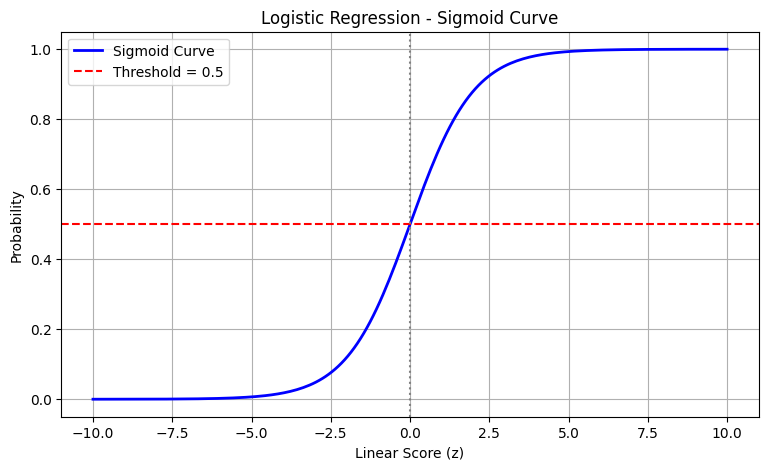

In [228]:

z_values = np.linspace(-10, 10, 200)

probabilities = 1 / (
    1 + np.exp(-z_values)
)

plt.figure(figsize=(9, 5))

plt.plot(
    z_values,
    probabilities,
    color='blue',
    linewidth=2,
    label='Sigmoid Curve'
)

plt.axhline(
    y=0.5,
    color='red',
    linestyle='--',
    label='Threshold = 0.5'
)

plt.axvline(
    x=0,
    color='gray',
    linestyle=':'
)

plt.title('Logistic Regression - Sigmoid Curve')
plt.xlabel('Linear Score (z)')
plt.ylabel('Probability')
plt.legend()
plt.grid(True)
plt.show()


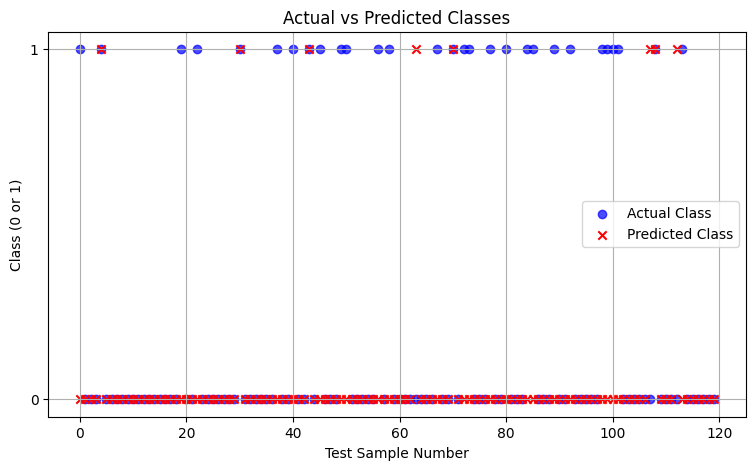

In [229]:

plt.figure(figsize=(9, 5))

sample_numbers = np.arange(len(y_test))

plt.scatter(
    sample_numbers,
    y_test,
    color='blue',
    label='Actual Class',
    alpha=0.7
)

plt.scatter(
    sample_numbers,
    y_pred,
    color='red',
    marker='x',
    label='Predicted Class'
)

plt.title('Actual vs Predicted Classes')
plt.xlabel('Test Sample Number')
plt.ylabel('Class (0 or 1)')
plt.yticks([0, 1])
plt.legend()
plt.grid(True)
plt.show()


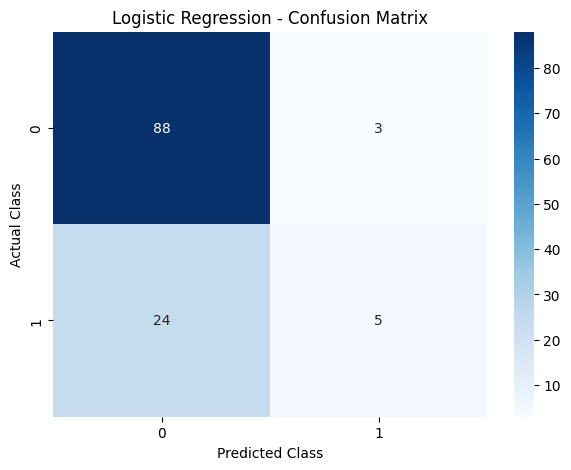

In [230]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()


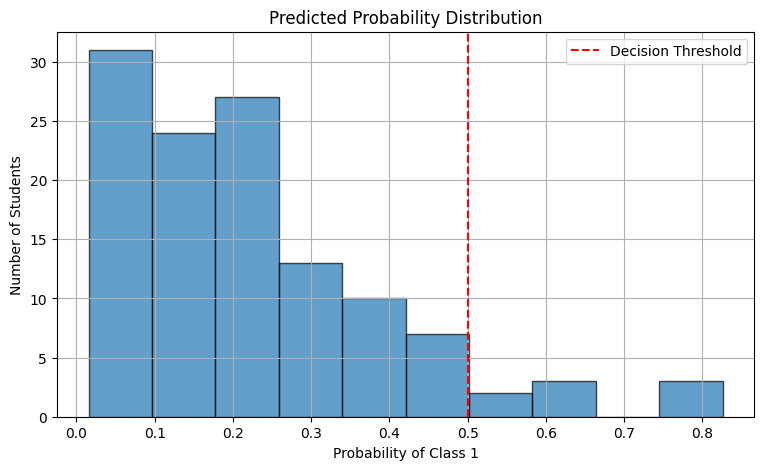

In [231]:


predicted_probabilities = model.predict_proba(
    X_test
)[:, 1]

plt.figure(figsize=(9, 5))

plt.hist(
    predicted_probabilities,
    bins=10,
    edgecolor='black',
    alpha=0.7
)

plt.axvline(
    x=0.5,
    color='red',
    linestyle='--',
    label='Decision Threshold'
)

plt.title('Predicted Probability Distribution')
plt.xlabel('Probability of Class 1')
plt.ylabel('Number of Students')
plt.legend()
plt.grid(True)
plt.show()


In [232]:

# New Student Details
new_student = pd.DataFrame([{
    "StudyHoursPerDay": 4.5,
    "AttendancePercent": 85,
    "PreviousExamScore": 65,
    "AssignmentsCompleted": 8,
    "SleepHours": 7
}])

# Predict using trained model
prediction = model.predict(new_student)[0]

# Get probability
probability = model.predict_proba(new_student)[0]

# Final Output
print("===== STUDENT PERFORMANCE PREDICTION =====")

print("Study Hours:", 4.5)
print("Attendance:", "85%")
print("Previous Exam Score:", 65)
print("Assignments Completed:", 8)
print("Sleep Hours:", 7)

print("\nPredicted Class:", prediction)
print("Probability of Fail:", round(probability[0] * 100, 2), "%")
print("Probability of Pass:", round(probability[1] * 100, 2), "%")

print("\nFinal Prediction:",
      "PASS" if prediction == 1 else "FAIL")


===== STUDENT PERFORMANCE PREDICTION =====
Study Hours: 4.5
Attendance: 85%
Previous Exam Score: 65
Assignments Completed: 8
Sleep Hours: 7

Predicted Class: 0
Probability of Fail: 57.41 %
Probability of Pass: 42.59 %

Final Prediction: FAIL


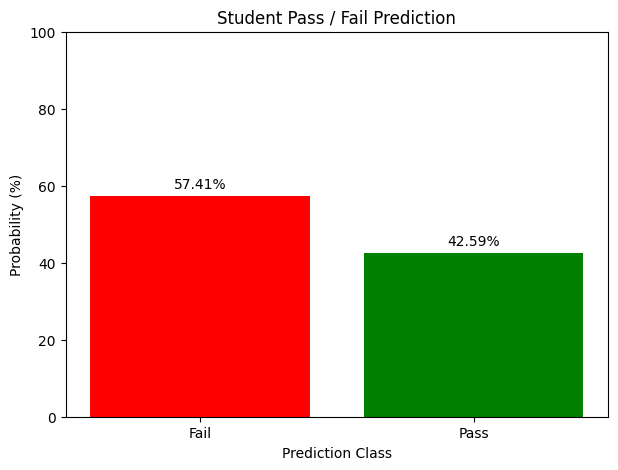

In [233]:

plt.figure(figsize=(7, 5))

plt.bar(
    ["Fail", "Pass"],
    probability * 100,
    color=["red", "green"]
)

plt.title("Student Pass / Fail Prediction")
plt.xlabel("Prediction Class")
plt.ylabel("Probability (%)")
plt.ylim(0, 100)

for i, value in enumerate(probability):
    plt.text(
        i,
        value * 100 + 2,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.show()


In [244]:
import pandas as pd
import os

# Find CSV file
file_name = "/content/fruit_dataset.csv"

# Load dataset
df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")

display(df.head())

Dataset Loaded Successfully!


,weight_g,length_cm,width_cm,color_score,fruit
0,111.0,17.5,3.3,2.9,Banana
1,130.0,18.4,3.7,2.6,Banana
2,190.0,7.9,8.9,6.1,Orange
3,169.0,7.1,7.0,7.6,Apple
4,173.0,8.2,8.5,6.1,Apple


In [246]:
print(df.columns)
print(df.shape)
print(df.info())

Index(['weight_g', 'length_cm', 'width_cm', 'color_score', 'fruit'], dtype='object')
(450, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   weight_g     450 non-null    float64
 1   length_cm    450 non-null    float64
 2   width_cm     450 non-null    float64
 3   color_score  450 non-null    float64
 4   fruit        450 non-null    object 
dtypes: float64(4), object(1)
memory usage: 17.7+ KB
None


In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [248]:

import pandas as pd
import os

# Find the existing CSV file
csv_files = [
    f for f in os.listdir("/content")
    if f.endswith(".csv")
    and f.startswith("fruit_dataset")
]

print("Found CSV Files:", csv_files)

# Load dataset
if csv_files:
    file_name = os.path.join("/content", csv_files[0])
    df = pd.read_csv(file_name)

    print("Dataset Loaded Successfully!")
    display(df.head())
else:
    print("CSV file not found!")


Found CSV Files: ['fruit_dataset.csv']
Dataset Loaded Successfully!


,weight_g,length_cm,width_cm,color_score,fruit
0,111.0,17.5,3.3,2.9,Banana
1,130.0,18.4,3.7,2.6,Banana
2,190.0,7.9,8.9,6.1,Orange
3,169.0,7.1,7.0,7.6,Apple
4,173.0,8.2,8.5,6.1,Apple


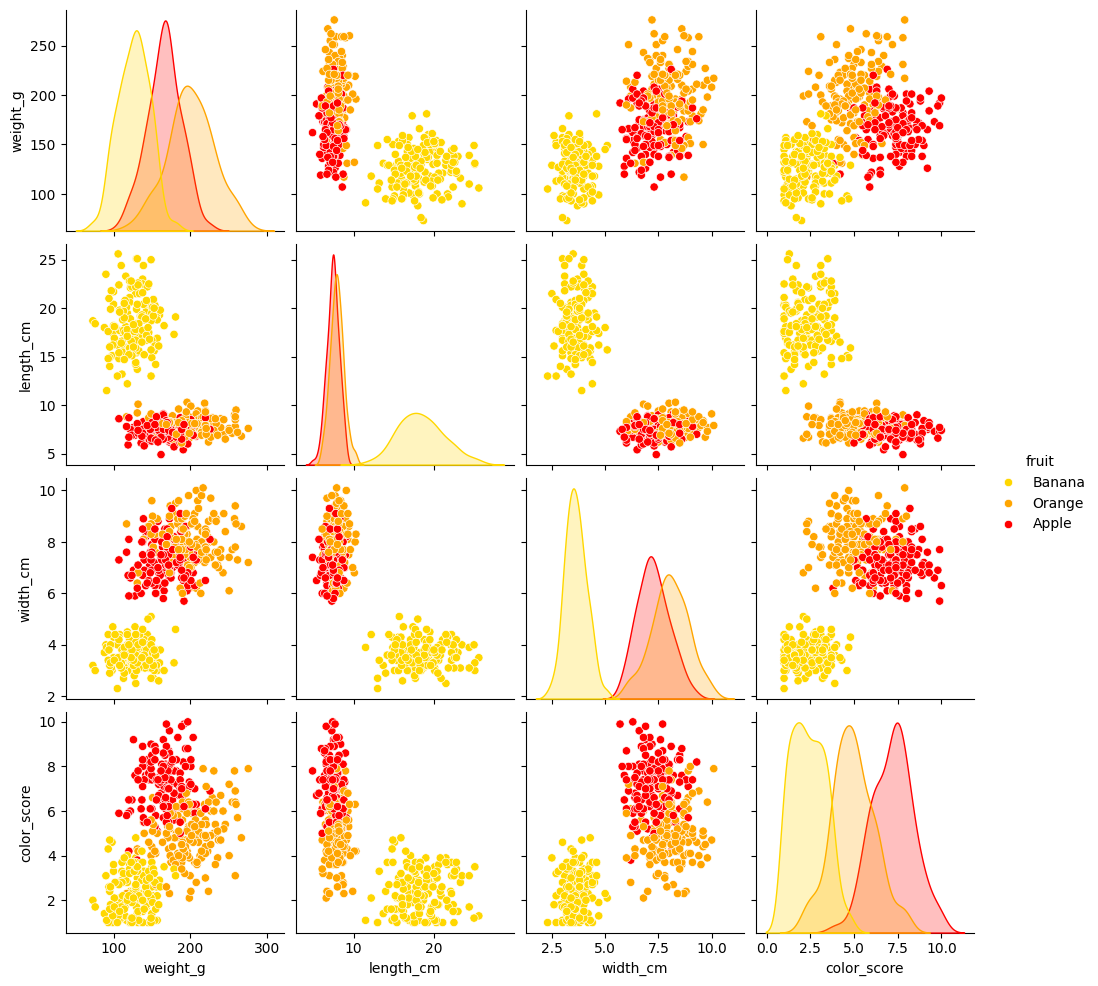

In [249]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Display pair plot
sns.pairplot(
    df,
    hue="fruit",
    palette={
        "Apple": "red",
        "Orange": "orange",
        "Banana": "gold"
    }
)

plt.show()


In [250]:
X = df[["weight_g", "length_cm", "width_cm", "color_score"]]
Y = df[["fruit"]]

In [251]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)
print("Train :" , len(X_train))
print("Test :" , len(X_test))

Train : 360
Test : 90


In [252]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [253]:
from sklearn.svm import SVC
model = SVC(kernel='linear', C=1, gamma='scale')
model.fit(X_train_scaled, Y_train.values.ravel())

SVC(C=1, kernel='linear')

In [254]:
model = SVC(kernel='rbf', C=1, gamma='scale')
model.fit(X_train_scaled, Y_train.values.ravel())
print("classes :", model.classes_)

classes : ['Apple' 'Banana' 'Orange']


In [255]:
new_fruit = pd.DataFrame([{
    "weight_g": 111,
    "length_cm": 17.8,
    "width_cm": 3.3,
    "color_score": 2.9
}])
print("Prediction :", model.predict(scaler.transform(new_fruit))[0])

Prediction : Banana


student_performance_logistic_regression

In [256]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [257]:

# Find Student Performance CSV
csv_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".csv")
    and f.startswith("student_performance_logistic_regression")
]

print("Found CSV Files:", csv_files)

if not csv_files:
    raise FileNotFoundError(
        "Upload the Student Performance CSV to Colab first."
    )

file_name = os.path.join("/content", sorted(csv_files)[0])

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
display(df.head())


Found CSV Files: ['student_performance_logistic_regression (2).csv', 'student_performance_logistic_regression.csv', 'student_performance_logistic_regression (1).csv']
Dataset Loaded Successfully!


,StudyHoursPerDay,AttendancePercent,PreviousExamScore,AssignmentsCompleted,SleepHours,Passed
0,5.5,71,56,8,6.3,0
1,4.3,61,75,10,5.0,0
2,3.0,75,49,4,7.9,0
3,1.9,65,43,2,7.2,0
4,1.0,79,60,0,6.8,1


In [258]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nClass Distribution:")
print(df["Passed"].value_counts())


Dataset Shape: (600, 6)

Column Names:
['StudyHoursPerDay', 'AttendancePercent', 'PreviousExamScore', 'AssignmentsCompleted', 'SleepHours', 'Passed']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   StudyHoursPerDay      600 non-null    float64
 1   AttendancePercent     600 non-null    int64  
 2   PreviousExamScore     600 non-null    int64  
 3   AssignmentsCompleted  600 non-null    int64  
 4   SleepHours            600 non-null    float64
 5   Passed                600 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 28.3 KB

Statistical Summary:


,StudyHoursPerDay,AttendancePercent,PreviousExamScore,AssignmentsCompleted,SleepHours,Passed
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,3.735500,78.608333,58.335000,5.073333,6.786500,0.240000
std,1.464843,11.743002,16.213603,3.220545,0.986216,0.427439
min,0.500000,48.000000,10.000000,0.000000,4.000000,0.000000
25%,2.800000,70.000000,47.000000,2.000000,6.100000,0.000000
50%,3.700000,79.000000,58.000000,5.000000,6.800000,0.000000
75%,4.700000,87.000000,69.000000,8.000000,7.400000,0.000000
max,9.000000,100.000000,100.000000,10.000000,10.000000,1.000000



Class Distribution:
Passed
0    456
1    144
Name: count, dtype: int64


In [259]:

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicates Before Cleaning:")
print(df.duplicated().sum())

# Remove missing values and duplicates
df = df.dropna().drop_duplicates().copy()

print("\nCleaned Dataset Shape:", df.shape)


Missing Values Before Cleaning:
StudyHoursPerDay        0
AttendancePercent       0
PreviousExamScore       0
AssignmentsCompleted    0
SleepHours              0
Passed                  0
dtype: int64

Duplicates Before Cleaning:
0

Cleaned Dataset Shape: (600, 6)


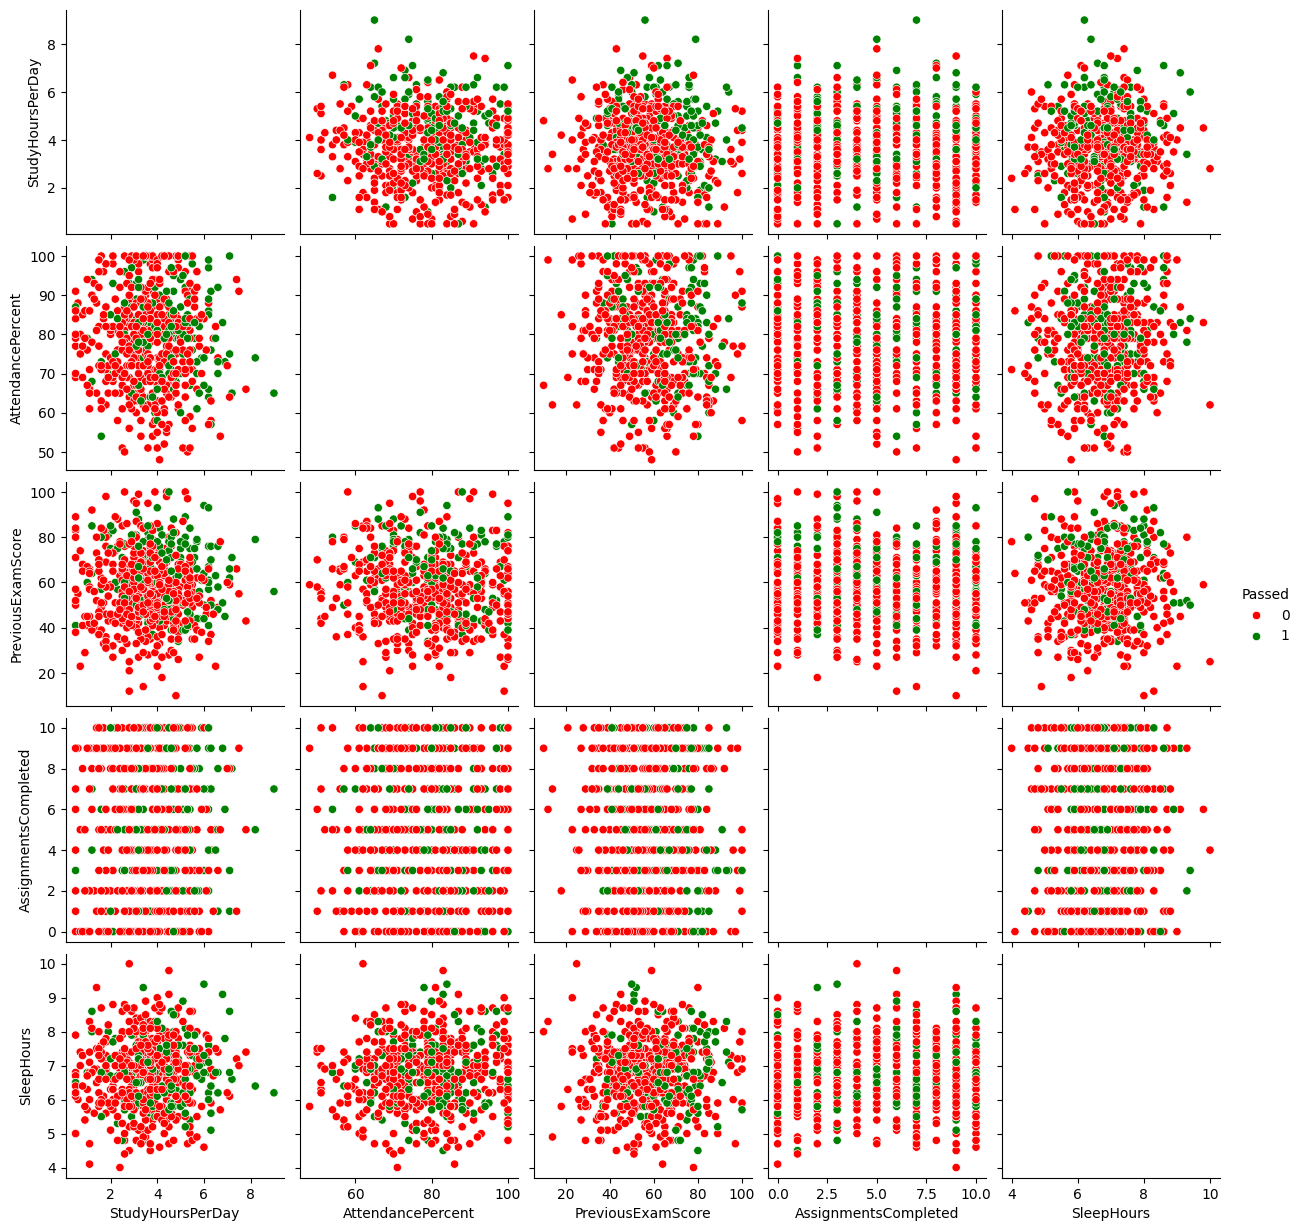

In [260]:

sns.pairplot(
    df,
    hue="Passed",
    palette={
        0: "red",
        1: "green"
    },
    diag_kind="gold"
)

plt.show()


In [261]:

feature_cols = [
    "StudyHoursPerDay",
    "AttendancePercent",
    "PreviousExamScore",
    "AssignmentsCompleted",
    "SleepHours"
]

X = df[feature_cols]
Y = df["Passed"]

print("Input Features:")
display(X.head())

print("Target:")
display(Y.head())


Input Features:


,StudyHoursPerDay,AttendancePercent,PreviousExamScore,AssignmentsCompleted,SleepHours
0,5.5,71,56,8,6.3
1,4.3,61,75,10,5.0
2,3.0,75,49,4,7.9
3,1.9,65,43,2,7.2
4,1.0,79,60,0,6.8


Target:


,Passed
0,0
1,0
2,0
3,0
4,1


In [267]:

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Train:", len(X_train))
print("Test:", len(X_test))


Train: 480
Test: 120


In [263]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Scaled Successfully!")

print("Scaled Training Data:")
print(X_train_scaled[:5])


Training Data Scaled Successfully!
Scaled Training Data:
[[-0.78888328  0.10918492  0.09096342  0.00843148 -1.12580975]
 [-1.80479449 -1.07999278 -1.02858637 -0.92551748  0.60132083]
 [ 0.15930052  0.10918492 -1.65055847  0.94238045  0.90610858]
 [ 0.36248276  0.02424365 -0.65540311  0.00843148 -0.61783017]
 [-1.33070259 -0.91011025 -1.52616405  0.31974781  0.19493716]]


In [268]:

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, Y_train)

logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression Model Trained!")
print("Classes:", logistic_model.classes_)


Logistic Regression Model Trained!
Classes: [0 1]


In [264]:

svm_linear = SVC(
    kernel="linear",
    C=1,
    gamma="scale"
)

svm_linear.fit(X_train_scaled, Y_train)

svm_linear_pred = svm_linear.predict(X_test_scaled)

print("Linear SVM Model Trained!")
print("Classes:", svm_linear.classes_)


Linear SVM Model Trained!
Classes: [0 1]


In [265]:

svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

svm_rbf.fit(X_train_scaled, Y_train)

svm_rbf_pred = svm_rbf.predict(X_test_scaled)

print("RBF SVM Model Trained!")
print("Classes:", svm_rbf.classes_)


RBF SVM Model Trained!
Classes: [0 1]


In [269]:

# Define models first
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

logistic_model = LogisticRegression(max_iter=1000)
svm_linear = SVC(kernel="linear")
svm_rbf = SVC(kernel="rbf")

# Train models
logistic_model.fit(X_train_scaled, Y_train)
svm_linear.fit(X_train_scaled, Y_train)
svm_rbf.fit(X_train_scaled, Y_train)

# Model dictionary
models = {
    "Logistic Regression": logistic_model,
    "Linear SVM": svm_linear,
    "RBF SVM": svm_rbf
}

results = []

# Model evaluation
for name, trained_model in models.items():

    y_pred = trained_model.predict(X_test_scaled)

    accuracy = accuracy_score(Y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))

    print(classification_report(
        Y_test,
        y_pred,
        target_names=["Fail", "Pass"],
        zero_division=0
    ))

# Comparison table
comparison = pd.DataFrame(results)
display(comparison)



Model: Logistic Regression
Accuracy: 0.775
              precision    recall  f1-score   support

        Fail       0.79      0.97      0.87        91
        Pass       0.62      0.17      0.27        29

    accuracy                           0.78       120
   macro avg       0.71      0.57      0.57       120
weighted avg       0.75      0.78      0.72       120


Model: Linear SVM
Accuracy: 0.7583
              precision    recall  f1-score   support

        Fail       0.76      1.00      0.86        91
        Pass       0.00      0.00      0.00        29

    accuracy                           0.76       120
   macro avg       0.38      0.50      0.43       120
weighted avg       0.58      0.76      0.65       120


Model: RBF SVM
Accuracy: 0.7833
              precision    recall  f1-score   support

        Fail       0.79      0.97      0.87        91
        Pass       0.67      0.21      0.32        29

    accuracy                           0.78       120
   macro avg   

,Model,Accuracy
0,Logistic Regression,0.775000
1,Linear SVM,0.758333
2,RBF SVM,0.783333


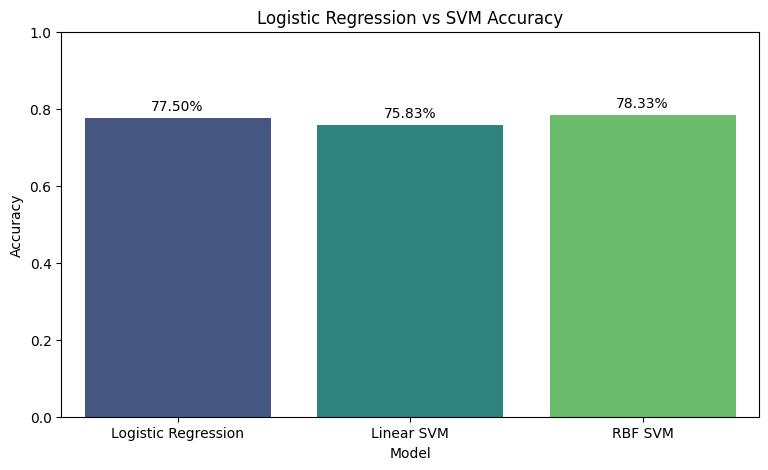

In [270]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Logistic Regression vs SVM Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, acc in enumerate(comparison["Accuracy"]):
    plt.text(
        i,
        acc + 0.02,
        f"{acc * 100:.2f}%",
        ha="center"
    )

plt.show()


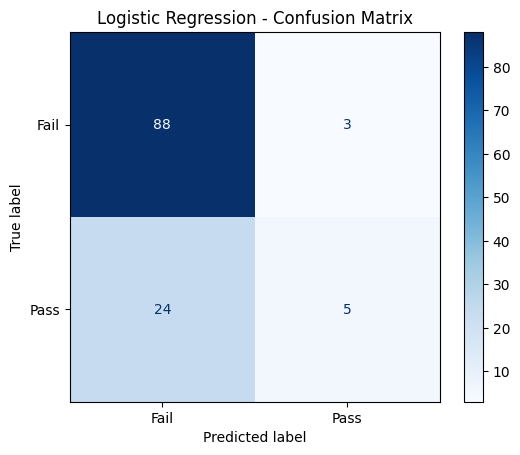

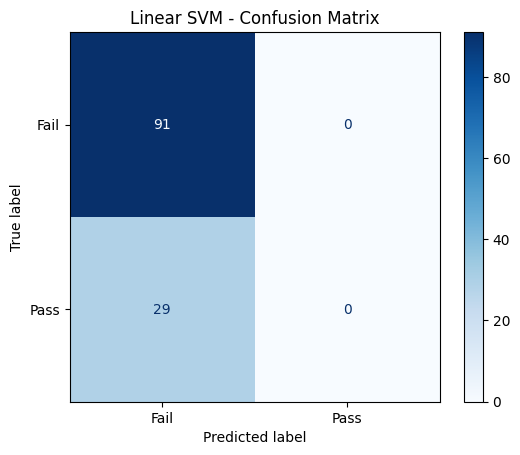

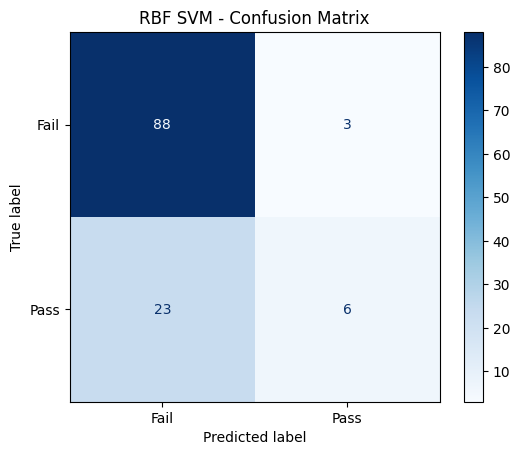

In [271]:

for name, trained_model in models.items():

    predictions = trained_model.predict(X_test_scaled)

    ConfusionMatrixDisplay.from_predictions(
        Y_test,
        predictions,
        display_labels=["Fail", "Pass"],
        cmap="Blues"
    )

    plt.title(name + " - Confusion Matrix")
    plt.show()


In [272]:

new_student = pd.DataFrame([{
    "StudyHoursPerDay": 4.5,
    "AttendancePercent": 85,
    "PreviousExamScore": 65,
    "AssignmentsCompleted": 8,
    "SleepHours": 7
}])

# Scale new student using training scaler
new_student_scaled = scaler.transform(new_student[feature_cols])

# Predict using all models
for name, trained_model in models.items():

    prediction = trained_model.predict(new_student_scaled)[0]

    print(
        name,
        ":",
        "PASS" if prediction == 1 else "FAIL"
    )

# Logistic Regression probability
probability = logistic_model.predict_proba(
    new_student_scaled
)[0]

print("\nLogistic Regression Probability")
print("Fail:", round(probability[0] * 100, 2), "%")
print("Pass:", round(probability[1] * 100, 2), "%")


Logistic Regression : FAIL
Linear SVM : FAIL
RBF SVM : FAIL

Logistic Regression Probability
Fail: 57.41 %
Pass: 42.59 %


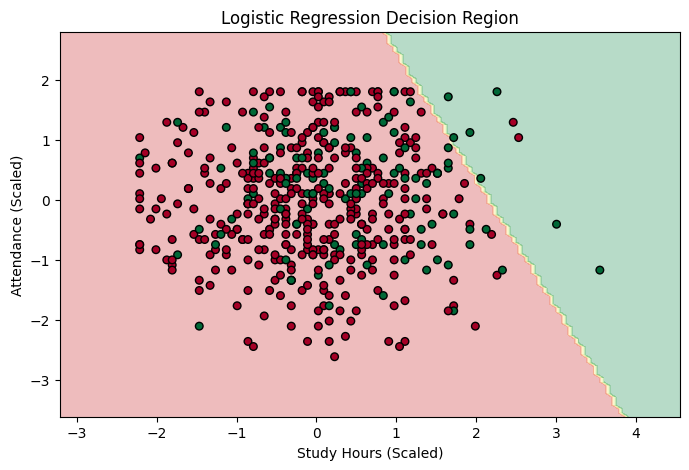

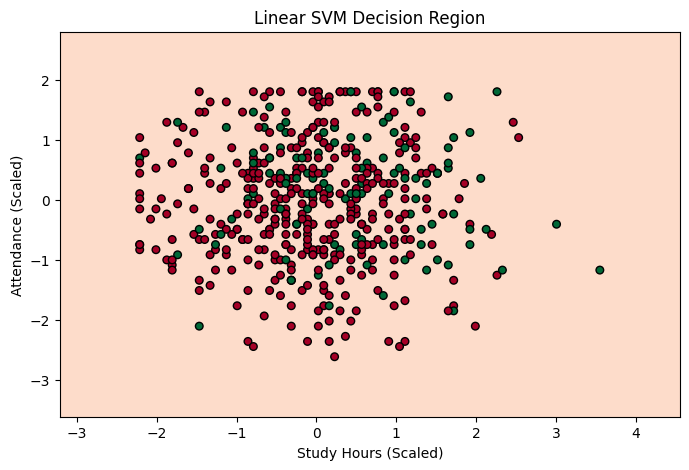

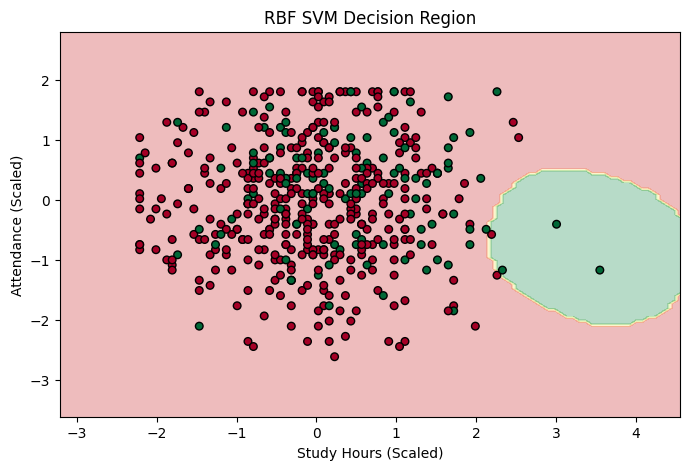

In [273]:

from sklearn.inspection import DecisionBoundaryDisplay

# Select two features for visualization
X_2d = df[[
    "StudyHoursPerDay",
    "AttendancePercent"
]]

y_2d = df["Passed"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(X2_train)

# Train visualization models
visual_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": SVC(kernel="linear", C=1),
    "RBF SVM": SVC(kernel="rbf", C=1)
}

for name, clf in visual_models.items():

    clf.fit(X2_train_scaled, y2_train)

    fig, ax = plt.subplots(figsize=(8, 5))

    DecisionBoundaryDisplay.from_estimator(
        clf,
        X2_train_scaled,
        response_method="predict",
        cmap="RdYlGn",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=y2_train,
        cmap="RdYlGn",
        edgecolors="black",
        s=30
    )

    ax.set_title(name + " Decision Region")
    ax.set_xlabel("Study Hours (Scaled)")
    ax.set_ylabel("Attendance (Scaled)")

    plt.show()


In [274]:

# Calculate linear score
z = logistic_model.decision_function(
    new_student_scaled
)[0]

# Apply sigmoid function
p = 1 / (1 + np.exp(-z))

print("Linear Score (z):", round(z, 4))
print("Sigmoid Probability:", round(p, 4))
print("Pass Probability:", round(p * 100, 2), "%")
print("Final Class:", "PASS" if p >= 0.5 else "FAIL")


Linear Score (z): -0.2985
Sigmoid Probability: 0.4259
Pass Probability: 42.59 %
Final Class: FAIL
